In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def draw_area(x,y,model):
  # 1. 그래프의 x,y 축의 범위 설정
  x_min,x_max = x[:,0].min()-1, x[:,0].max()+1
  y_min,y_max = x[:,1].min()-1, x[:,1].max()+1

  # 2. 만든 범위를 0.01 간격으로 촘촘한 값을 생성
  pos_x = np.arange(x_min,x_max,0.01)
  pos_y = np.arange(y_min,y_max,0.01)
  # print(f'pos X : {pos_x}')
  # print(f'pos Y : {pos_y}')

  # 3. 격자 형태로 x,y 배열을 만든다.
  xx,yy = np.meshgrid(pos_x, pos_y)

  # 4. 두 배열을 합쳐서 일렬로 만들어 준다.
  # 두 배열을 합칠때 각각 1차원 이어야 하는데 xx, yy 는 2차원이다.
  # 그래서 ravel() 함수를 통해 1차원으로 만든다.
  val = np.c_[xx.ravel(),yy.ravel()]
  # print(val) # [[x,y],[x,y],...]

  # 5. 이렇게 생성된 값으로 모델에 예측을 시킨다.
  z = model.predict(val)
  print(z)

  # 6. 영역을 그려준다.
  plt.scatter(x[:,0],x[:,1], c=y)
  plt.contourf(xx,yy,z.reshape(xx.shape),alpha=0.3)
  plt.show()

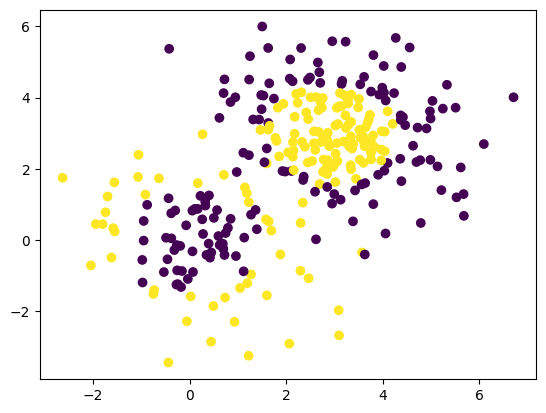

In [ ]:
# 1. 데이터 호출
arr = np.load('/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/data/gaussian.npz')
x = arr['x']
y = arr['y']

# 2. 데이터 확인
plt.scatter(x[:,0],x[:,1], c=y)
plt.show()

In [ ]:
import sklearn.ensemble as en
import sklearn.tree as tree
import sklearn.model_selection as ms
# ada boost
# 의사결정트리를 2단계 깊이로 9개를 만들어서 순차적으로 보완해 나간다.
# 기본은 의사결정나무를 사용한다.(약한 분류기 조건에 잘 맞아서)
model = en.AdaBoostClassifier(
  n_estimators=9
  ,estimator=tree.DecisionTreeClassifier(max_depth=2)
).fit(x,y)

print(f'cross score: {ms.cross_val_score(model,x,y,cv=5).mean()}')

cross score: 0.8366666666666667


[0 0 0 ... 0 0 0]


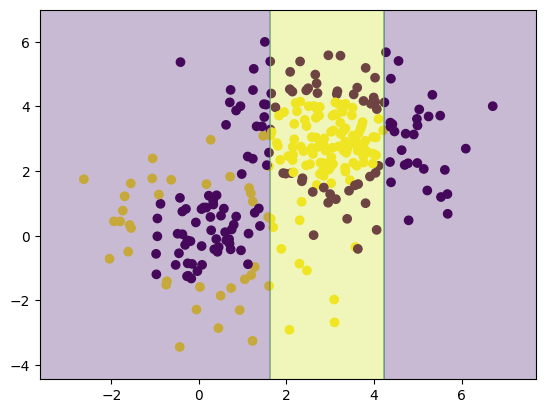

[1 1 1 ... 0 0 0]


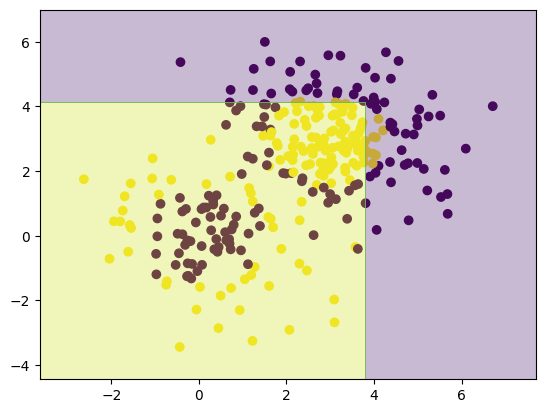

[1 1 1 ... 0 0 0]


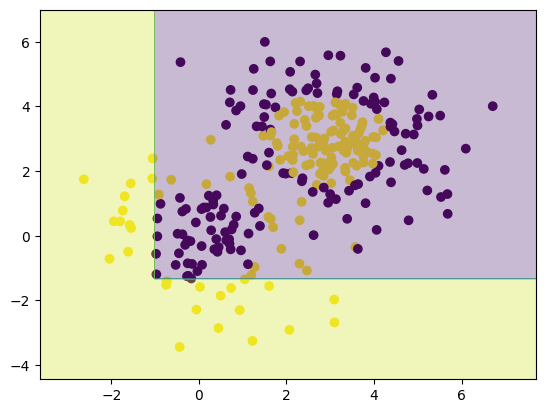

[1 1 1 ... 0 0 0]


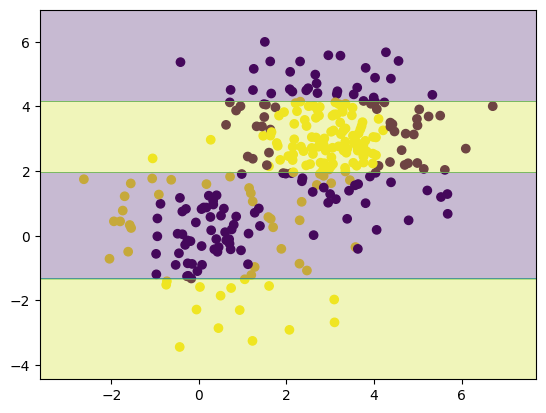

[1 1 1 ... 0 0 0]


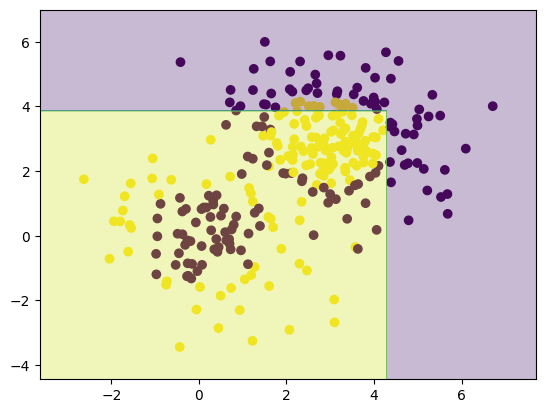

[1 1 1 ... 0 0 0]


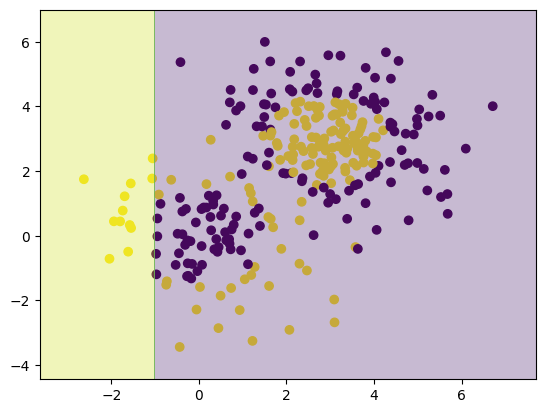

[0 0 0 ... 0 0 0]


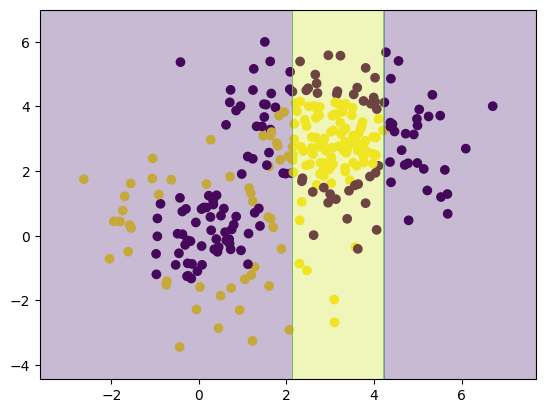

[1 1 1 ... 1 1 1]


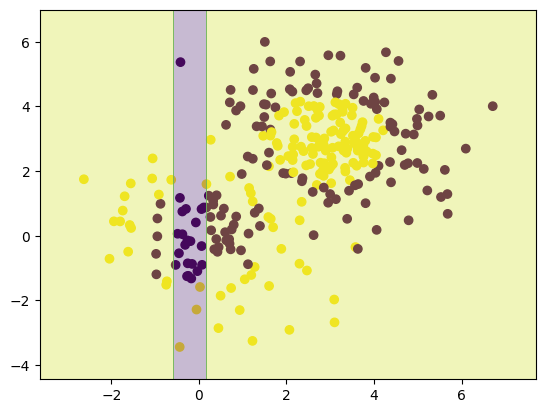

[1 1 1 ... 0 0 0]


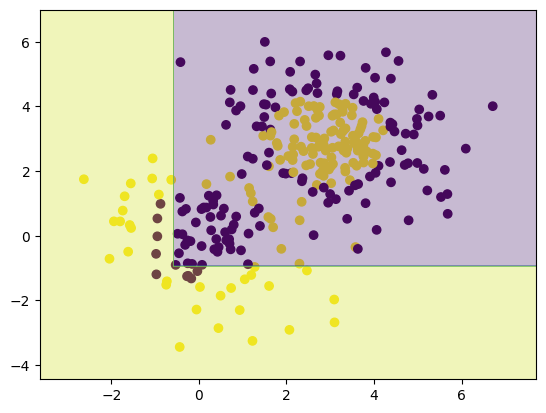

[1 1 1 ... 0 0 0]


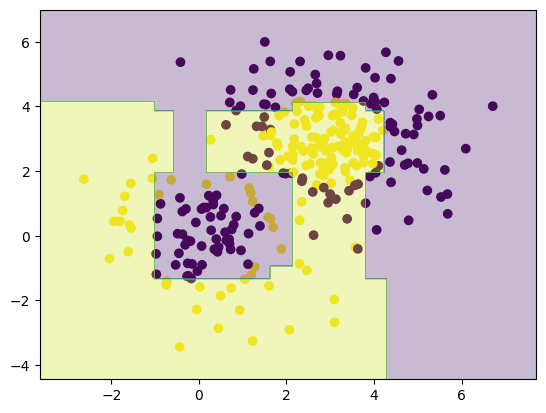

In [ ]:
for m in model.estimators_:
  draw_area(x,y,m)

draw_area(x,y,model)